# Illicit Bitcoin Transaction Detection on the Elliptic Dataset
**BCSE209L — Machine Learning · VIT Vellore, SCOPE · B.Tech CSE (Data Science)**
Team: ADITHIYA SR (23BDS0045) · SHRIJANKIRITH T (23BDS0034) · RAJITA SK (23BDS0010)

This notebook runs the full system described in the project demonstration deck:
dataset → preprocessing → feature-block separation → tabular + graph representation →
four controlled detection arms → illicit/licit classification → per-time-step evaluation.

Section numbers follow the deck. Everything runs on a laptop CPU.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, torch
from IPython.display import Image, display
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 220)
torch.set_num_threads(2)

from src import config as C, data as D, elliptical, models as M, experiment, analysis, trace

# Training all arms x 5 seeds takes ~1-2 h on a laptop CPU. The submitted results are
# saved in results/predictions.parquet; set RUN_TRAINING = True to regenerate them.
RUN_TRAINING = False

## 1. Research objective
Classify Bitcoin transactions as illicit or licit under a protocol that (i) separates the local
transaction features (LF) from the neighbourhood-aggregated features (AF), (ii) compares tree
ensembles against graph neural networks with that confound removed, and (iii) reports
minority-class performance **per time step**, before and after the dark-market shutdown at t = 43.

> **Feature-count note.** The published "94 local features" include the time step. Slide 4 states that
> time step is used to build the split and is not a predictor, so this implementation uses
> **LF = 93 columns, AF = 72 columns, 165 predictors in total.**

## 2–4. Input data and integrity validation

In [2]:
nodes, edges = D.load_raw()
checks = D.validate(nodes, edges)   # raises if any hard check fails
checks

,check,observed,expected,pass
0,Transaction nodes,203769,203769,True
1,Directed edges,234355,234355,True
2,Feature columns used (LF + AF),165,165,True
3,Missing feature values,0,0,True
4,Duplicate txId,0,0,True
5,Duplicate edges,0,0,True
6,Self-loops,0,0,True
7,Edges to unknown txId,0,0,True
8,Edges crossing time steps,0,0,True
9,Time steps,49,49,True


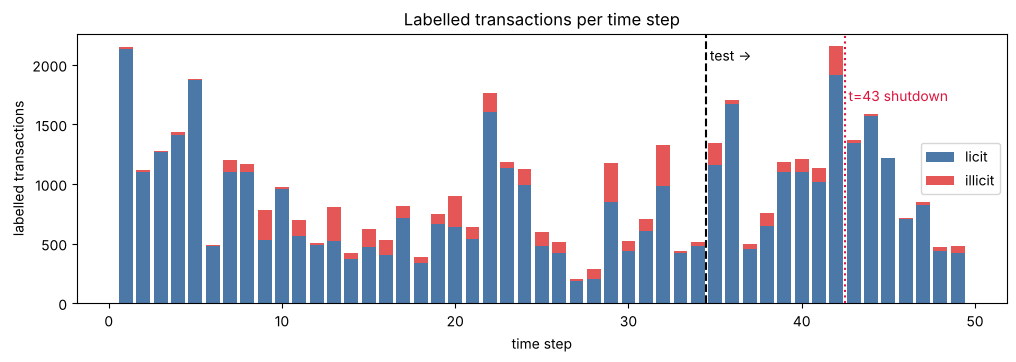

Illicit share of ALL nodes: 2.2%  |  of labelled nodes: 9.8%  |  unlabelled: 77.1%


In [3]:
import matplotlib.pyplot as plt
lab = nodes[nodes.label >= 0]
cnt = lab.groupby(["time_step", "label"]).size().unstack(fill_value=0).rename(columns={0: "licit", 1: "illicit"})
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(cnt.index, cnt.licit, color="#4C78A8", label="licit"); ax.bar(cnt.index, cnt.illicit, bottom=cnt.licit, color="#E45756", label="illicit")
ax.axvline(34.5, color="k", ls="--"); ax.text(34.7, ax.get_ylim()[1]*.9, "test →")
ax.axvline(42.5, color="crimson", ls=":"); ax.text(42.7, ax.get_ylim()[1]*.75, "t=43 shutdown", color="crimson")
ax.set(xlabel="time step", ylabel="labelled transactions", title="Labelled transactions per time step"); ax.legend(); plt.show()
print(f"Illicit share of ALL nodes: {(nodes.label==1).mean():.1%}  |  of labelled nodes: {(lab.label==1).mean():.1%}  |  unlabelled: {(nodes.label==-1).mean():.1%}")

## 5. Preprocessing
* Missing values / duplicates: validated above (none).
* Target encoding: class 1 → illicit (1), class 2 → licit (0), unknown → excluded from supervised training.
* **Scaling**: `StandardScaler` fitted on time steps 1–34 only, then applied to the test period.
* **Outliers**: counted and reported, never removed (they may be the illicit cases).
* **Split**: frozen temporal split, train t1–34, test t35–49. Hyper-parameters are tuned on a
  validation slice inside the training period (fit t1–28, validate t29–34).
* **Imbalance**: one illicit-class weight (= #licit / #illicit in training) used in every arm's loss.

In [4]:
d = D.prepare()
display(D.split_summary(d))
w = M.illicit_weight(d.y[d.mask(C.TRAIN_STEPS)])
print(f"Illicit class weight shared by all arms: {w:.3f}")
print("Scaler fitted on", int(d.mask(C.TRAIN_STEPS, labelled=False).sum()), "training-period nodes; test-period mean of LF_1 after scaling =",
      round(float(d.X[d.mask(C.TEST_STEPS, labelled=False), 0].mean()), 3), "(not 0, as expected when no test statistics leak in)")

,split,labelled,illicit,licit,illicit_%
0,train (1-34),29894,3462,26432,11.58
1,test (35-49),16670,1083,15587,6.50
2,tune-train (1-28),25207,2542,22665,10.08
3,tune-val (29-34),4687,920,3767,19.63


Illicit class weight shared by all arms: 7.635
Scaler fitted on 136265 training-period nodes; test-period mean of LF_1 after scaling = -0.044 (not 0, as expected when no test statistics leak in)


## 6. Data representation and the elliptical-distribution question
"Elliptic" is the company that released the data, not a statement about elliptical distributions.
We **test** the assumption: fit mean and covariance on licit training transactions (LF block),
compute squared Mahalanobis distances, and compare them with the chi-square distribution they would
follow if licit points formed one ellipsoid. Then we use the distance as an unsupervised detector.

In [5]:
ell = elliptical.run(d)
display(ell["gof"]); display(ell["detector"])

,quantity,value
0,Feature block,LF
1,Dimensions in block,93
2,Effective rank (chi-square df),80
3,Licit training points,26432
4,Mean d^2 (expected = df),80.0
5,Median d^2 (expected),27.9 (79.3)
6,Share above chi2 95% quantile (expected 5%),11.8%
7,Mardia kurtosis b2 (expected p(p+2)),"177,877 (6,560)"
8,KS statistic vs chi2(df),0.745
9,KS p-value,0.00e+00


,rule,flagged_%,precision,recall,illicit_F1,PR_AUC (score=d^2),PR_AUC of random ranking
0,flag if d^2 > chi2_80(0.975) = 106.6,14.1,0.006,0.012,0.008,0.038,0.065


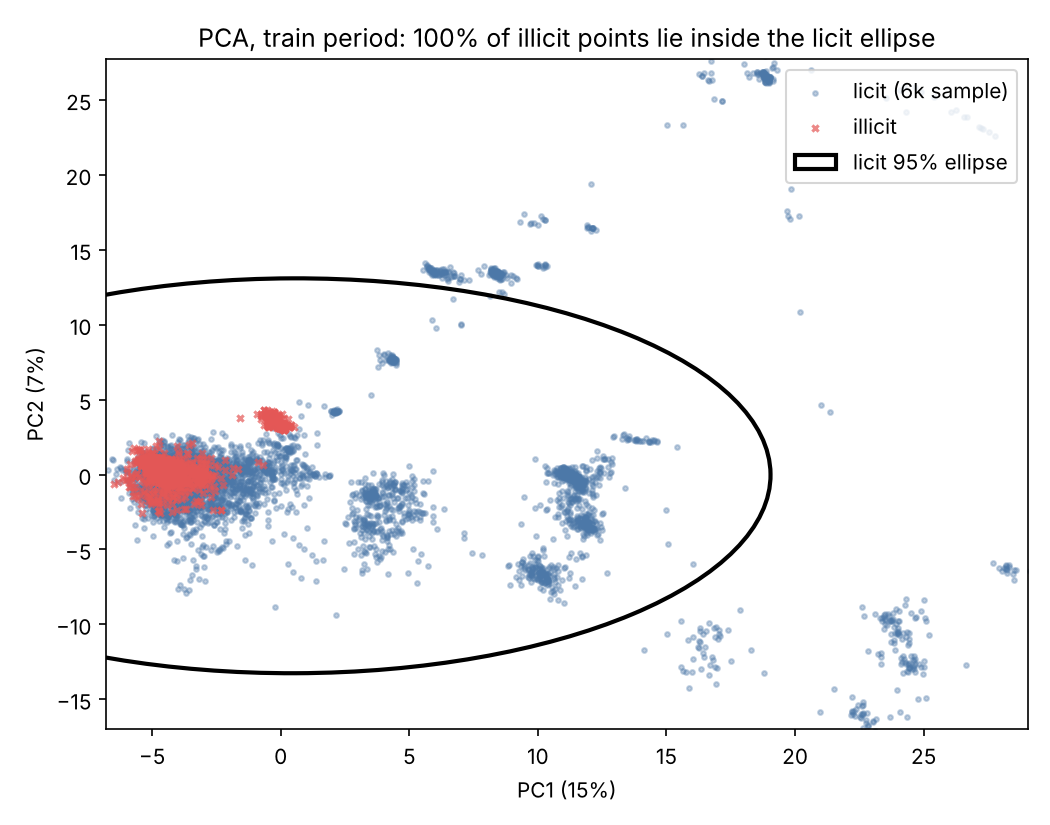

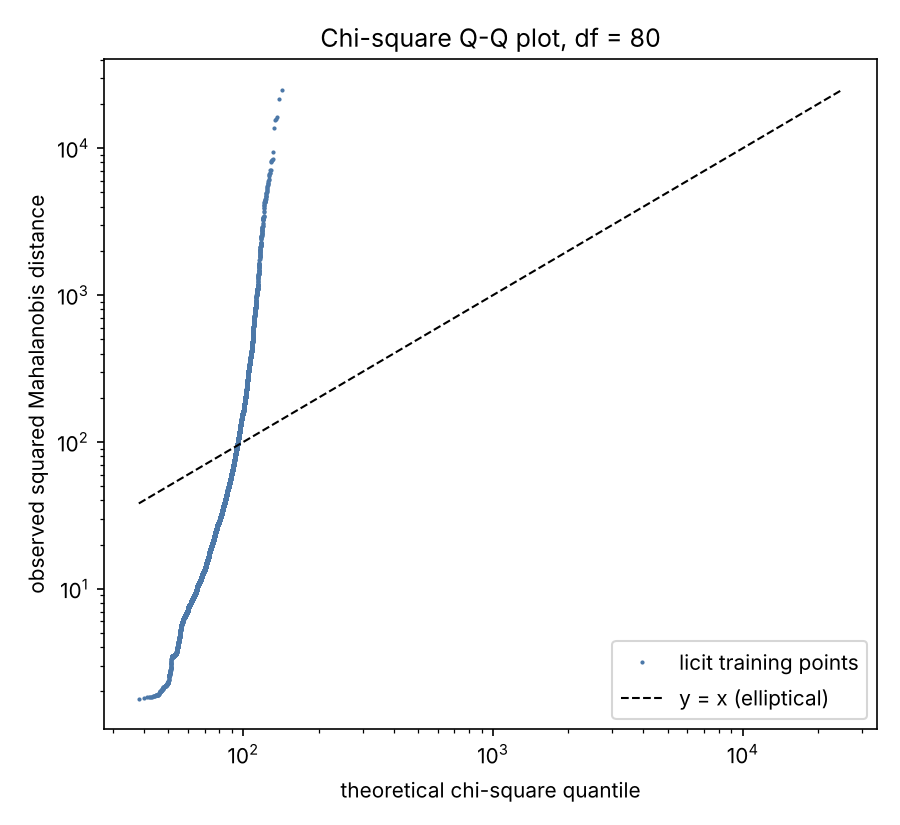

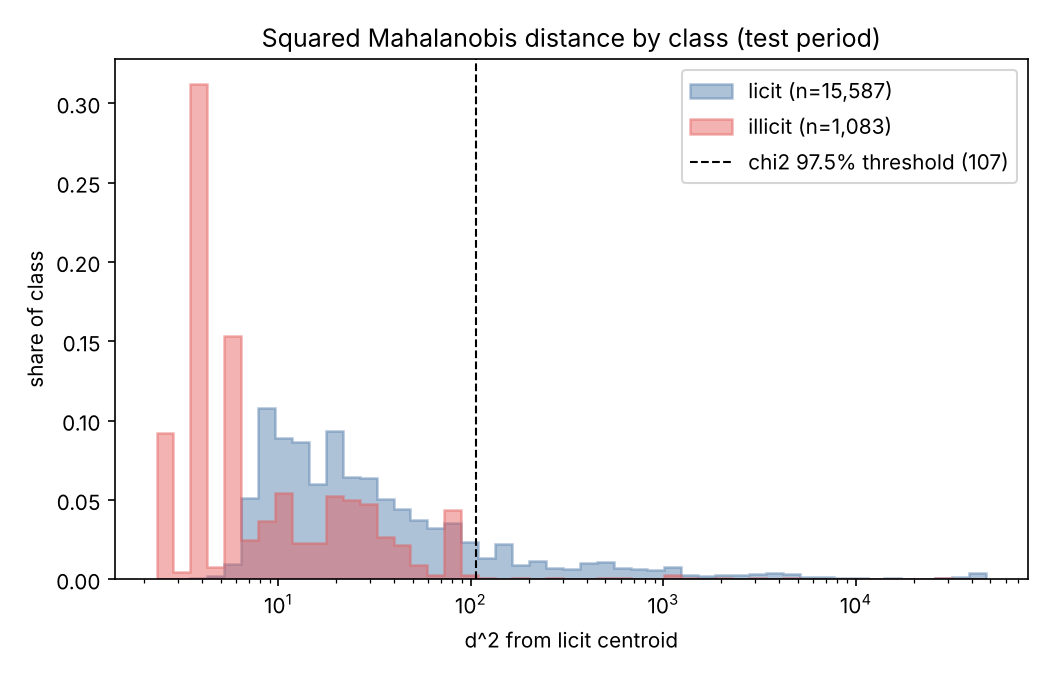

In [6]:
for f in ["elliptical_pca_ellipse.png", "elliptical_chi2_qq.png", "elliptical_distance_hist.png"]:
    display(Image(filename=str(C.FIGURES / f), width=650))

## 7. Proposed detection method — four controlled arms
| Arm | Model family | Input | Question it answers |
|---|---|---|---|
| A1 | XGBoost / Random Forest | LF (93) | non-graph baseline |
| A2 | XGBoost / Random Forest | LF + AF (165) | value of precomputed 1-hop aggregates (A2 vs A1) |
| A3 | GraphSAGE / GCN | LF (93) + edges | learned message passing without aggregates (A3 vs A2) |
| A4 | GraphSAGE / GCN | LF + AF + edges | are aggregates and message passing redundant? |

Held constant: split, class weight, 5 seeds (0–4), threshold 0.5, illicit-class metrics.
GNNs: 2 graph-conv layers + linear head, ReLU, dropout 0.3, Adam (weight decay 5e-4), full-batch,
edges used in both directions. Each period is its own sub-graph because no edge crosses a time step.

In [7]:
if RUN_TRAINING:
    experiment.run_all(d, seeds=C.SEEDS, do_ablation=True)
cfg = json.load(open(C.RESULTS / "run_config.json"))
display(pd.DataFrame(cfg["best_params"].items(), columns=["arm/model", "selected hyper-parameters (validation t29-34)"]))
tuning = pd.read_csv(C.TABLES / "tuning_results.csv")
display(tuning.sort_values(["arm", "model", "val_PR_AUC"], ascending=[True, True, False]).groupby(["arm", "model"]).head(2))

,arm/model,selected hyper-parameters (validation t29-34)
0,A1/XGBoost,"{'max_depth': 8, 'n_estimators': 200, 'learnin..."
1,A1/RandomForest,"{'max_depth': 20, 'max_features': 'sqrt', 'n_e..."
2,A2/XGBoost,"{'max_depth': 6, 'n_estimators': 200, 'learnin..."
3,A2/RandomForest,"{'max_depth': None, 'max_features': 'sqrt', 'n..."
4,A3/GraphSAGE,"{'hidden': 64, 'lr': 0.01, 'epochs': 180}"
5,A3/GCN,"{'hidden': 128, 'lr': 0.01, 'epochs': 190}"
6,A4/GraphSAGE,"{'hidden': 64, 'lr': 0.01, 'epochs': 100}"
7,A4/GCN,"{'hidden': 128, 'lr': 0.01, 'epochs': 170}"


,max_depth,n_estimators,learning_rate,val_PR_AUC,arm,model,max_features,hidden,lr,epochs
8,20.0,300.0,NaN,0.986956,A1,RandomForest,sqrt,NaN,NaN,NaN
6,NaN,300.0,NaN,0.986336,A1,RandomForest,sqrt,NaN,NaN,NaN
4,8.0,200.0,0.1,0.977130,A1,XGBoost,NaN,NaN,NaN,NaN
2,6.0,200.0,0.1,0.975757,A1,XGBoost,NaN,NaN,NaN,NaN
16,NaN,300.0,NaN,0.987144,A2,RandomForest,sqrt,NaN,NaN,NaN
18,20.0,300.0,NaN,0.987049,A2,RandomForest,sqrt,NaN,NaN,NaN
12,6.0,200.0,0.1,0.985379,A2,XGBoost,NaN,NaN,NaN,NaN
13,6.0,500.0,0.1,0.984308,A2,XGBoost,NaN,NaN,NaN,NaN
26,NaN,NaN,NaN,0.931089,A3,GCN,NaN,128.0,0.010,190.0
24,NaN,NaN,NaN,0.917860,A3,GCN,NaN,64.0,0.010,130.0


## 9–11. Results: classification and per-time-step evaluation

In [8]:
summary = analysis.run(d)   # rebuilds every table and figure from the saved predictions
main = pd.read_csv(C.TABLES / "main_results.csv")
main[main.sampling == "weights"].drop(columns="sampling")

arm        model  sampling illicit_F1 (pooled)     precision        recall        PR_AUC       ROC_AUC      accuracy F1 mean over steps F1 pre t35-42 F1 post t43-49     post - pre
 A1 RandomForest   weights       0.743 ± 0.001 0.749 ± 0.002 0.738 ± 0.001 0.789 ± 0.001 0.916 ± 0.002 0.967 ± 0.000      0.458 ± 0.001 0.835 ± 0.001  0.026 ± 0.001 -0.809 ± 0.001
 A1      XGBoost   weights       0.743 ± 0.005 0.760 ± 0.010 0.727 ± 0.003 0.784 ± 0.002 0.917 ± 0.005 0.967 ± 0.001      0.459 ± 0.003 0.836 ± 0.005  0.029 ± 0.002 -0.807 ± 0.005
 A2 RandomForest   weights       0.808 ± 0.004 0.917 ± 0.010 0.723 ± 0.002 0.798 ± 0.001 0.939 ± 0.002 0.978 ± 0.001      0.494 ± 0.005 0.884 ± 0.006  0.048 ± 0.005 -0.836 ± 0.005
 A2      XGBoost   weights       0.792 ± 0.007 0.858 ± 0.018 0.736 ± 0.001 0.801 ± 0.002 0.930 ± 0.004 0.975 ± 0.001      0.487 ± 0.004 0.883 ± 0.007  0.036 ± 0.003 -0.847 ± 0.007
 A3          GCN   weights       0.381 ± 0.045 0.285 ± 0.075 0.624 ± 0.085 0.408 ± 0.048 0.860 ± 0.0

,arm,model,illicit_F1 (pooled),precision,recall,PR_AUC,ROC_AUC,accuracy,F1 mean over steps,F1 pre t35-42,F1 post t43-49,post - pre
0,A1,RandomForest,0.743 ± 0.001,0.749 ± 0.002,0.738 ± 0.001,0.789 ± 0.001,0.916 ± 0.002,0.967 ± 0.000,0.458 ± 0.001,0.835 ± 0.001,0.026 ± 0.001,-0.809 ± 0.001
1,A1,XGBoost,0.743 ± 0.005,0.760 ± 0.010,0.727 ± 0.003,0.784 ± 0.002,0.917 ± 0.005,0.967 ± 0.001,0.459 ± 0.003,0.836 ± 0.005,0.029 ± 0.002,-0.807 ± 0.005
2,A2,RandomForest,0.808 ± 0.004,0.917 ± 0.010,0.723 ± 0.002,0.798 ± 0.001,0.939 ± 0.002,0.978 ± 0.001,0.494 ± 0.005,0.884 ± 0.006,0.048 ± 0.005,-0.836 ± 0.005
3,A2,XGBoost,0.792 ± 0.007,0.858 ± 0.018,0.736 ± 0.001,0.801 ± 0.002,0.930 ± 0.004,0.975 ± 0.001,0.487 ± 0.004,0.883 ± 0.007,0.036 ± 0.003,-0.847 ± 0.007
4,A3,GCN,0.381 ± 0.045,0.285 ± 0.075,0.624 ± 0.085,0.408 ± 0.048,0.860 ± 0.007,0.864 ± 0.040,0.290 ± 0.016,0.506 ± 0.032,0.043 ± 0.008,-0.463 ± 0.036
5,A3,GraphSAGE,0.557 ± 0.044,0.486 ± 0.084,0.672 ± 0.050,0.669 ± 0.025,0.904 ± 0.010,0.929 ± 0.019,0.378 ± 0.013,0.668 ± 0.033,0.047 ± 0.014,-0.620 ± 0.045
6,A4,GCN,0.591 ± 0.025,0.743 ± 0.113,0.502 ± 0.063,0.628 ± 0.037,0.887 ± 0.006,0.955 ± 0.007,0.337 ± 0.012,0.611 ± 0.034,0.024 ± 0.029,-0.587 ± 0.059
7,A4,GraphSAGE,0.615 ± 0.055,0.612 ± 0.095,0.624 ± 0.037,0.588 ± 0.058,0.900 ± 0.012,0.949 ± 0.011,0.375 ± 0.040,0.656 ± 0.059,0.053 ± 0.022,-0.604 ± 0.045


### Per-time-step illicit F1 (the central figure)

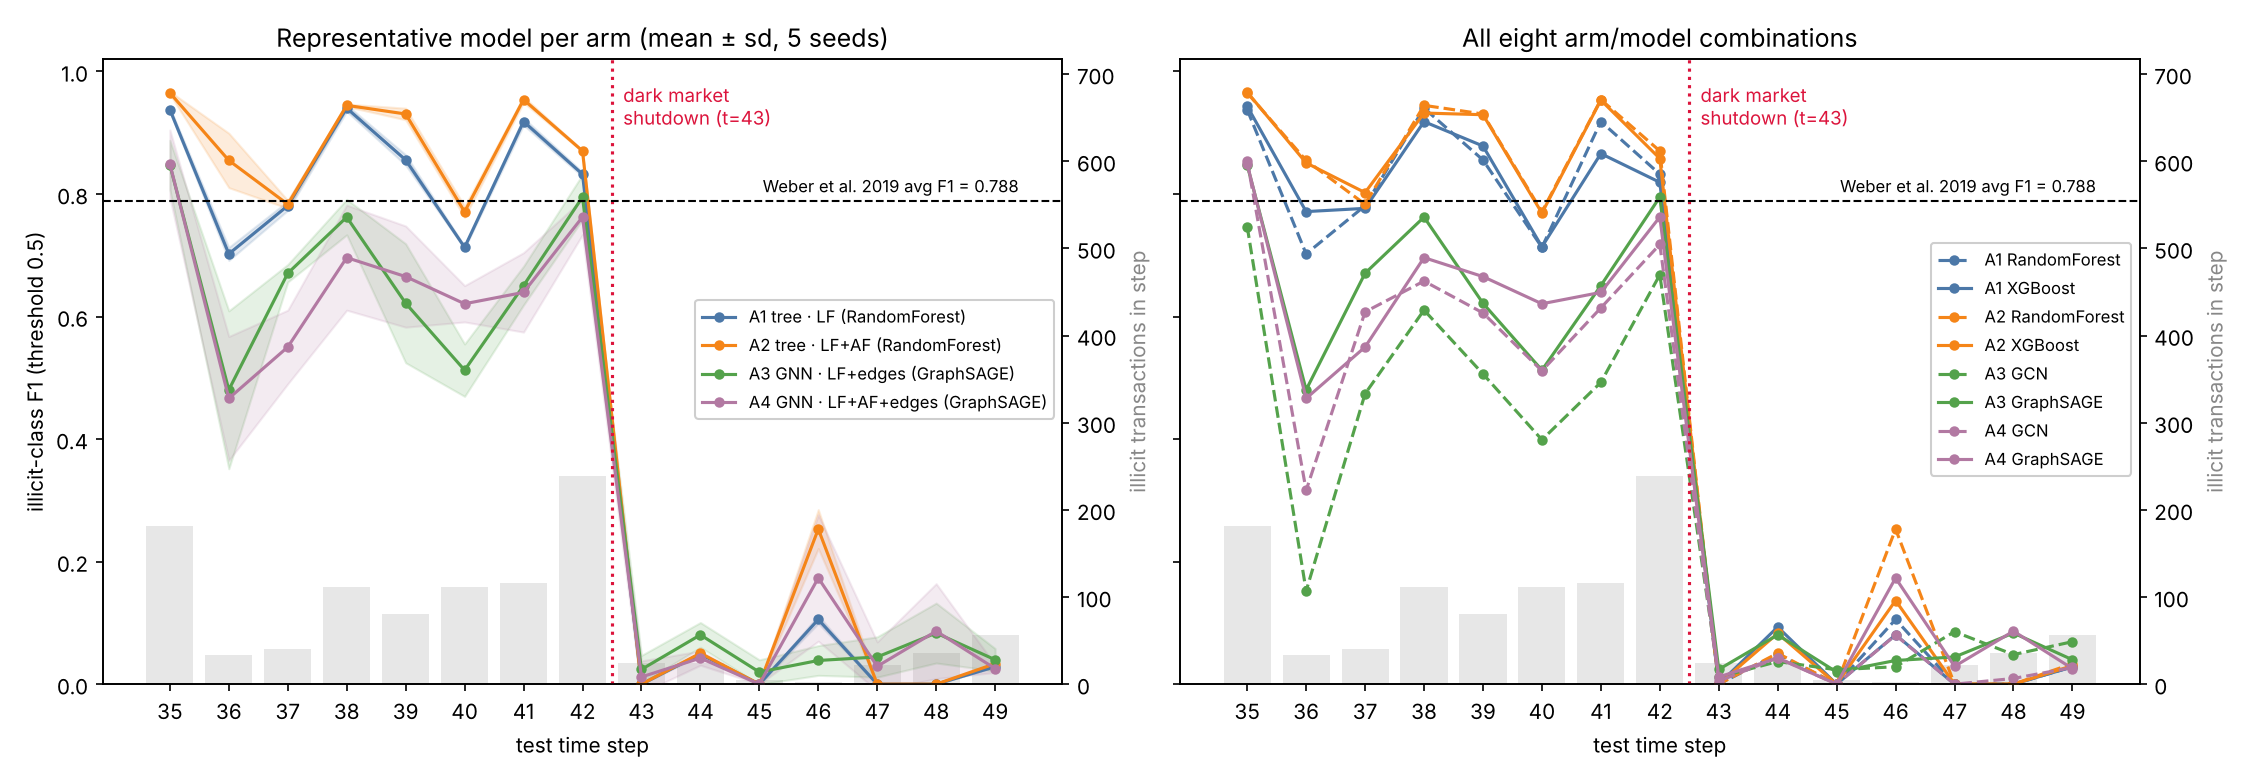

arm                 A1                   A2             A3               A4          
model     RandomForest XGBoost RandomForest XGBoost    GCN GraphSAGE    GCN GraphSAGE
time_step                                                                            
35               0.938   0.943        0.965   0.966  0.747     0.847  0.854     0.849
36               0.702   0.771        0.855   0.851  0.152     0.480  0.316     0.466
37               0.781   0.777        0.783   0.802  0.474     0.671  0.608     0.550
38               0.940   0.918        0.945   0.932  0.611     0.762  0.658     0.696
39               0.856   0.878        0.931   0.929  0.506     0.622  0.606     0.665
40               0.713   0.714        0.771   0.769  0.399     0.512  0.511     0.621
41               0.918   0.866        0.954   0.953  0.493     0.651  0.614     0.639
42               0.832   0.819        0.870   0.858  0.668     0.795  0.718     0.762
43               0.000   0.000        0.000   0.000  0.011     0.024  0.005     0.012
44               0.049   0.093        0.051   0.083  0.037     0.080  0.043     0.043
45               0.000   0.000        0.000   0.000  0.024     0.020  0.000     0.000
46               0.106   0.081        0.253   0.137  0.028     0.039  0.080     0.173
47               0.000   0.000        0.000   0.000  0.086     0.044  0.000     0.029
48               0.000   0.000        0.000   0.000  0.048     0.083  0.009     0.087
49               0.028   0.028        0.033   0.030  0.069     0.040  0.027     0.025

In [9]:
display(Image(filename=str(C.FIGURES / "drift_curve_illicit_f1.png")))
pd.read_csv(C.TABLES / "per_step_f1_wide.csv", header=[0, 1], index_col=0)

### Pre-drift vs post-drift

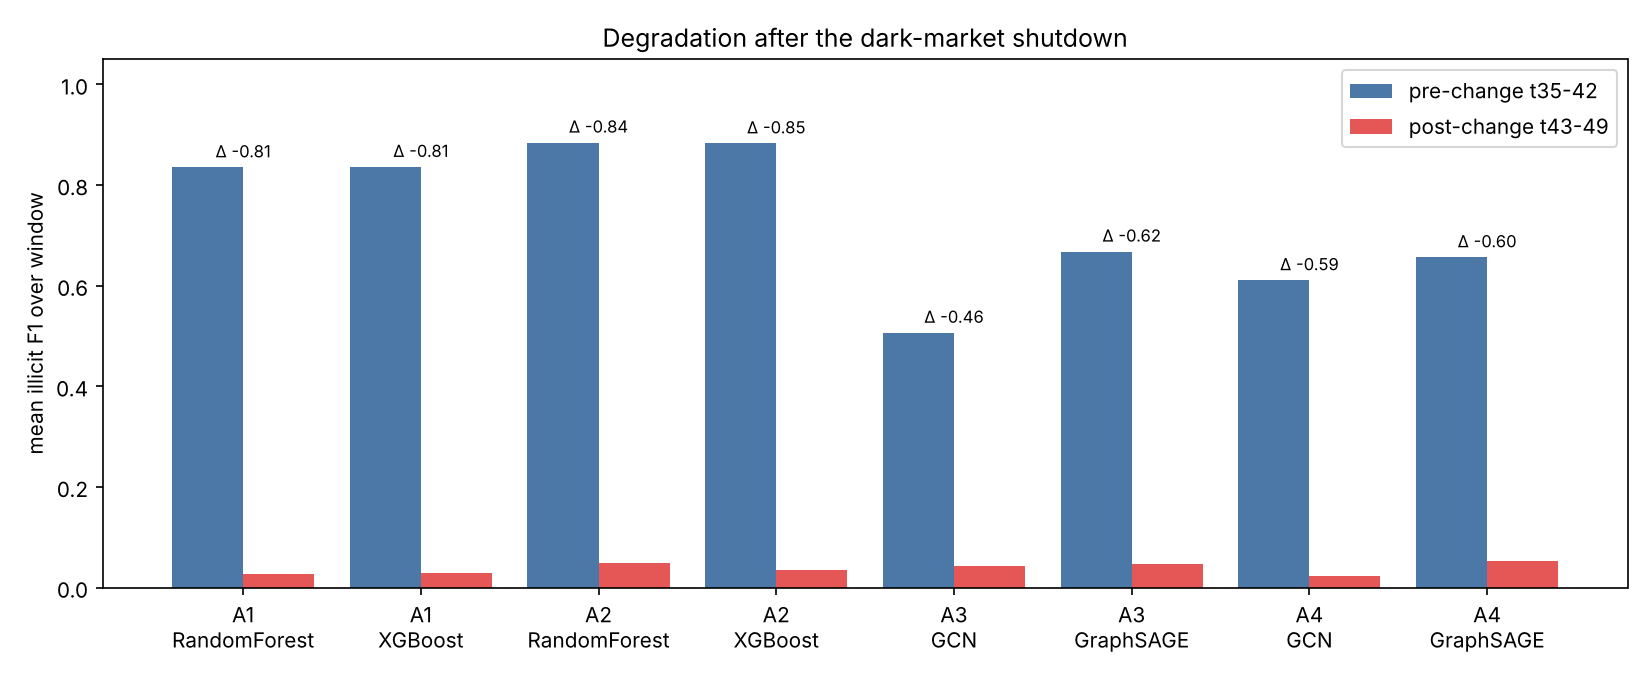

,arm,model,F1 pre t35-42,F1 post t43-49,post - pre
0,A1,RandomForest,0.835 ± 0.001,0.026 ± 0.001,-0.809 ± 0.001
1,A1,XGBoost,0.836 ± 0.005,0.029 ± 0.002,-0.807 ± 0.005
2,A2,RandomForest,0.884 ± 0.006,0.048 ± 0.005,-0.836 ± 0.005
3,A2,XGBoost,0.883 ± 0.007,0.036 ± 0.003,-0.847 ± 0.007
4,A3,GCN,0.506 ± 0.032,0.043 ± 0.008,-0.463 ± 0.036
5,A3,GraphSAGE,0.668 ± 0.033,0.047 ± 0.014,-0.620 ± 0.045
6,A4,GCN,0.611 ± 0.034,0.024 ± 0.029,-0.587 ± 0.059
7,A4,GraphSAGE,0.656 ± 0.059,0.053 ± 0.022,-0.604 ± 0.045


In [10]:
display(Image(filename=str(C.FIGURES / "pre_vs_post_f1.png"), width=850))
main[main.sampling == "weights"][["arm", "model", "F1 pre t35-42", "F1 post t43-49", "post - pre"]]

### Precision–recall curves

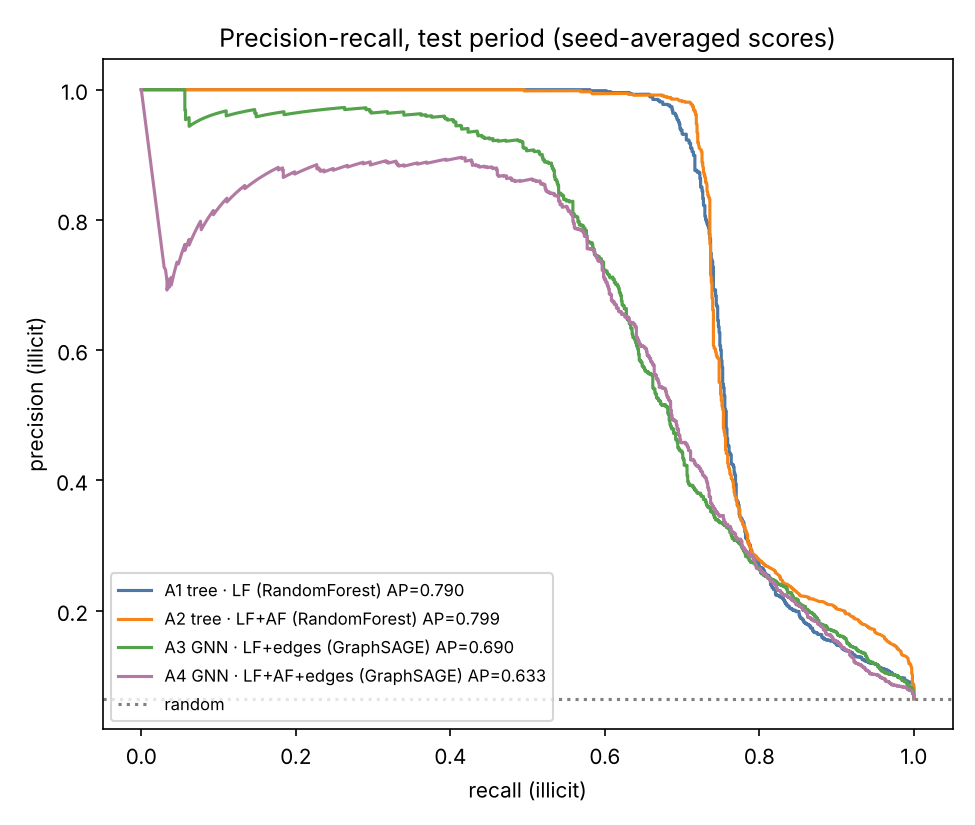

In [11]:
display(Image(filename=str(C.FIGURES / "pr_curves.png"), width=560))

### Confusion matrices per time step (representative model per arm, mean over seeds)

In [12]:
rep = json.load(open(C.RESULTS / "analysis_meta.json"))["representative"]
cm = pd.read_csv(C.TABLES / "per_step_f1_and_confusion.csv")
cm = cm[(cm.sampling == "weights") & cm.apply(lambda r: rep[r.arm] == r.model, axis=1)]
cm.pivot_table(index="time_step", columns="arm", values=["tp", "fp", "fn"]).round(1)

fn                      fp                        tp                     
arm          A1    A2    A3    A4    A1    A2     A3    A4     A1     A2     A3     A4
time_step                                                                             
35          5.8   5.0   7.6  16.4  17.6   7.8   56.2  43.4  176.2  177.0  174.4  165.6
36          0.0   3.4   5.4   7.4  28.0   6.6   63.6  55.0   33.0   29.6   27.6   25.6
37         12.2  14.0  14.8  17.4   3.4   0.4   10.0  20.0   27.8   26.0   25.2   22.6
38          9.0  10.2  14.8  19.6   4.0   1.6   45.8  63.0  102.0  100.8   96.2   91.4
39          5.8   6.0  27.8  27.8  19.6   5.2   35.0  26.0   75.2   75.0   53.2   53.2
40         36.0  38.6  52.0  51.0  25.2   5.0   61.0  23.4   76.0   73.4   60.0   61.0
41          7.0   8.0  35.6  40.6  12.4   2.4   51.6  45.0  109.0  108.0   80.4   75.4
42         43.4  49.2  44.6  63.4  35.4   7.4   57.0  45.8  195.6  189.8  194.4  175.6
43         24.0  24.0  21.4  23.6  10.6   1.2  153.2  43.8    0.0    0.0    2.6    0.4
44         22.0  23.0  16.8  23.0  55.6  14.6  138.2  25.6    2.0    1.0    7.2    1.0
45          5.0   5.0   4.4   5.0  16.0  10.0   59.6  20.0    0.0    0.0    0.6    0.0
46          1.0   1.0   1.2   1.2  16.0   5.0   35.6   5.6    1.0    1.0    0.8    0.8
47         22.0  22.0  20.8  21.6   8.6   1.0   30.0   4.0    0.0    0.0    1.2    0.4
48         36.0  36.0  34.0  34.2   2.6   0.0    7.4   4.0    0.0    0.0    2.0    1.8
49         55.0  55.0  54.4  55.0  13.2   2.8   20.2  25.4    1.0    1.0    1.6    1.0

### Feature-block attribution before vs after the change point

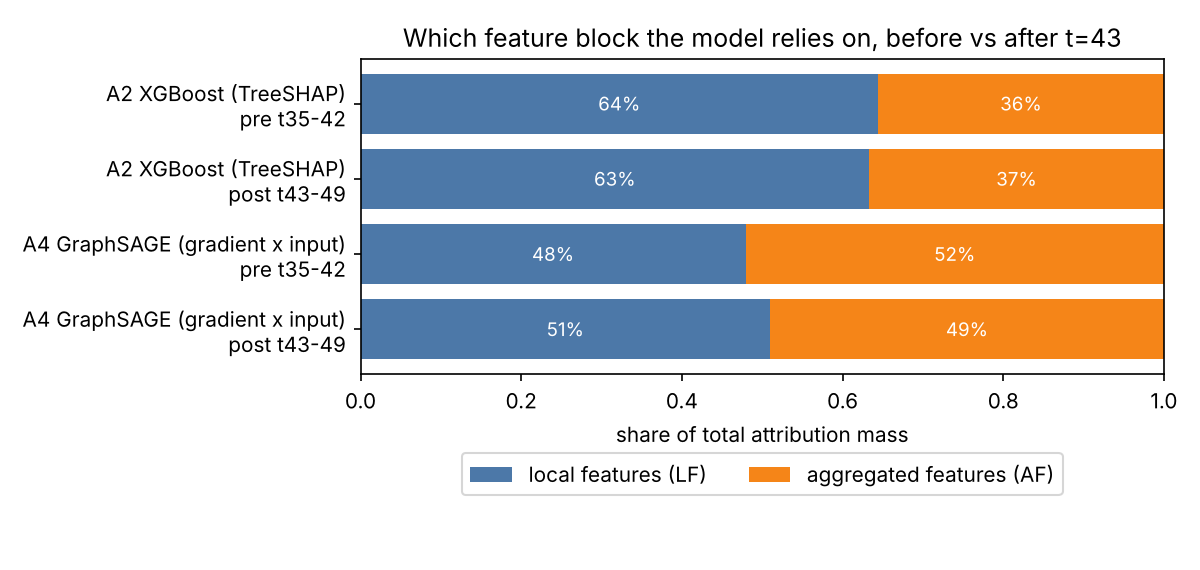

,window,rows,LF_share,AF_share,n,model
0,pre t35-42,all,0.6441,0.3559,9983,A2 XGBoost (TreeSHAP)
1,pre t35-42,illicit,0.6562,0.3438,914,A2 XGBoost (TreeSHAP)
2,post t43-49,all,0.6330,0.3670,6687,A2 XGBoost (TreeSHAP)
3,post t43-49,illicit,0.6181,0.3819,169,A2 XGBoost (TreeSHAP)
4,pre t35-42,all,0.4792,0.5208,9983,A4 GraphSAGE (gradient x input)
5,pre t35-42,illicit,0.4057,0.5943,914,A4 GraphSAGE (gradient x input)
6,post t43-49,all,0.5096,0.4904,6687,A4 GraphSAGE (gradient x input)
7,post t43-49,illicit,0.4228,0.5772,169,A4 GraphSAGE (gradient x input)


window,post t43-49,pre t35-42
rank,,
1,LF_53,LF_53
2,LF_59,LF_59
3,AF_32,LF_90
4,LF_46,LF_46
5,LF_90,LF_65
6,LF_3,AF_32
7,LF_65,LF_3
8,AF_68,LF_58
9,LF_58,LF_16


In [13]:
display(Image(filename=str(C.FIGURES / "feature_block_attribution.png"), width=800))
display(pd.read_csv(C.TABLES / "feature_block_attribution.csv"))
pd.read_csv(C.TABLES / "top_shap_features_pre_post.csv").pivot(index="rank", columns="window", values="feature")

### Sampling ablation: class weights vs NCL-SMOTE (XGBoost, A1 and A2)

In [14]:
main[main.model == "XGBoost"][["arm", "sampling", "illicit_F1 (pooled)", "PR_AUC", "F1 pre t35-42", "F1 post t43-49"]]

,arm,sampling,illicit_F1 (pooled),PR_AUC,F1 pre t35-42,F1 post t43-49
1,A1,weights,0.743 ± 0.005,0.784 ± 0.002,0.836 ± 0.005,0.029 ± 0.002
3,A2,weights,0.792 ± 0.007,0.801 ± 0.002,0.883 ± 0.007,0.036 ± 0.003
8,A1,ncl_smote,0.748 ± 0.008,0.794 ± 0.003,0.842 ± 0.007,0.051 ± 0.006
9,A2,ncl_smote,0.814 ± 0.004,0.816 ± 0.002,0.898 ± 0.003,0.041 ± 0.009


## 8. System workflow demonstration — one real test transaction traced end to end

**(a) An illicit transaction the system catches**

In [15]:
pd.set_option("display.max_colwidth", None)
tx = trace.pick_example(d, step=38, caught=True)
trace.trace(d, tx, rep)

,stage,what happens to this transaction,state after the stage
0,Input,"txId 40467500 at time step 38, 165 feature values, 1 incoming and 1 outgoing edges. True label: illicit.",Raw node record + edges
1,Preprocessing,Integrity checks pass. Raw LF_1 = -0.1638 becomes -0.1604 after scaling with training-period (t1-34) statistics. Assigned to the test set.,"Scaled vector, test set"
2,Feature block separation,"LF vector of 93 values (first three: [-0.16, 0.031, 1.419]), AF vector of 72 values.","LF (93), AF (72)"
3,Representation,"Row 25484 of X (203,769 x 165) for the tree arms; node 25484 of G with 2 undirected neighbours for the graph arms.","Row in X, node in G"
4,Elliptical check,Squared Mahalanobis distance 10.7 vs chi-square(80) 97.5% threshold 106.6.,Inside the licit ellipsoid — the elliptical rule would miss it
5,Detection model,"A1 (RandomForest) = 0.711, A2 (RandomForest) = 0.810, A3 (GraphSAGE) = 0.819, A4 (GraphSAGE) = 0.999",Four probability scores
6,Classification,"Threshold 0.5: predicted ILLICIT by ['A1', 'A2', 'A3', 'A4'].",4/4 arms predict illicit
7,Evaluation,Added to the confusion matrix for time step 38 (pre-change window).,One entry in the t=38 metric set


**(b) An illicit transaction it misses** — useful for error analysis

In [16]:
tx = trace.pick_example(d, step=38, caught=False)
trace.trace(d, tx, rep)

,stage,what happens to this transaction,state after the stage
0,Input,"txId 115275152 at time step 38, 165 feature values, 2 incoming and 1 outgoing edges. True label: illicit.",Raw node record + edges
1,Preprocessing,Integrity checks pass. Raw LF_1 = -0.1727 becomes -0.1683 after scaling with training-period (t1-34) statistics. Assigned to the test set.,"Scaled vector, test set"
2,Feature block separation,"LF vector of 93 values (first three: [-0.168, 1.081, 2.001]), AF vector of 72 values.","LF (93), AF (72)"
3,Representation,"Row 84958 of X (203,769 x 165) for the tree arms; node 84958 of G with 3 undirected neighbours for the graph arms.","Row in X, node in G"
4,Elliptical check,Squared Mahalanobis distance 22.2 vs chi-square(80) 97.5% threshold 106.6.,Inside the licit ellipsoid — the elliptical rule would miss it
5,Detection model,"A1 (RandomForest) = 0.051, A2 (RandomForest) = 0.057, A3 (GraphSAGE) = 0.134, A4 (GraphSAGE) = 0.303",Four probability scores
6,Classification,Threshold 0.5: predicted ILLICIT by no arm.,0/4 arms predict illicit
7,Evaluation,Added to the confusion matrix for time step 38 (pre-change window).,One entry in the t=38 metric set


## Ranked alert list (expected output, slide 9)

In [17]:
meta = json.load(open(C.RESULTS / "analysis_meta.json"))
arm, model = meta["alert_model"].split("/")
alerts = pd.read_csv(C.RESULTS / f"alert_list_{arm}_{model}.csv")
print(f"Alert model (best validation PR-AUC): {meta['alert_model']}")
for k in [50, 100, 250, 500, 1000]:
    print(f"  top {k:>4}: precision {alerts.cum_precision.iloc[k-1]:.3f}, recall {alerts.cum_recall.iloc[k-1]:.3f}")
alerts.head(15)

Alert model (best validation PR-AUC): A2/RandomForest
  top   50: precision 1.000, recall 0.046
  top  100: precision 1.000, recall 0.092
  top  250: precision 1.000, recall 0.231
  top  500: precision 1.000, recall 0.462
  top 1000: precision 0.797, recall 0.736


,rank_labelled,txId,time_step,risk_score,score_sd,predicted,true_label,cum_precision,cum_recall
0,1,68956752,35,1.0,0.0,illicit,illicit,1.0,0.000923
1,2,68980512,35,1.0,0.0,illicit,illicit,1.0,0.001847
2,3,70361270,35,1.0,0.0,illicit,illicit,1.0,0.002770
3,4,70361267,35,1.0,0.0,illicit,illicit,1.0,0.003693
4,5,70361272,35,1.0,0.0,illicit,illicit,1.0,0.004617
5,6,70361153,35,1.0,0.0,illicit,illicit,1.0,0.005540
6,7,70408671,35,1.0,0.0,illicit,illicit,1.0,0.006464
7,8,70361268,35,1.0,0.0,illicit,illicit,1.0,0.007387
8,9,67687673,35,1.0,0.0,illicit,illicit,1.0,0.008310
9,10,54879907,35,1.0,0.0,illicit,illicit,1.0,0.009234


## Conclusions
Numbers are mean ± sd over 5 seeds, test period t35–49, threshold 0.5 (see `results/tables/main_results.csv`).

1. **The elliptical assumption fails, and distance from "normal" points the wrong way.** Squared Mahalanobis
   distances of licit training points do not follow chi-square (KS = 0.75, p ≈ 0; Mardia kurtosis ≈ 27× its
   expected value). Used as an unsupervised detector, d² scores *below* random (PR-AUC 0.038 vs 0.065 base rate)
   because illicit transactions sit in a dense region close to the licit centroid. This reproduces
   Lorenz et al. (2020) and is the reason a supervised method is needed.
2. **Aggregated features are worth about +0.05–0.07 F1 to tree models (A2 vs A1).** Random Forest rises from
   0.743 to 0.808 pooled illicit F1, mostly through precision (0.75 → 0.92). A2 Random Forest reproduces
   Weber et al.'s published 0.788 (RF on all features).
3. **Learned message passing does not beat precomputed aggregates (A3 vs A2).** The best GNN on local features
   (GraphSAGE, 0.557) is well below the tree ensemble given the 1-hop aggregates (0.79–0.81), and below even the
   no-graph tree baseline A1 (0.743). GNNs also vary more across seeds (sd 0.03–0.06 vs ≤ 0.007).
4. **For GNNs, aggregates and message passing overlap (A4 vs A3).** Adding AF raises thresholded F1
   (GraphSAGE 0.557 → 0.615, GCN 0.381 → 0.591), mainly by raising precision. But GraphSAGE's PR-AUC falls
   (0.669 → 0.588), so its overall ranking gets worse. The evidence is mixed: much of what the aggregates
   carry is already learned by message passing. Neither GNN reaches the tree arms. GraphSAGE beats GCN in both
   GNN arms.
5. **Every arm collapses after the dark-market shutdown.** Mean illicit F1 falls from 0.51–0.88 in t35–42 to
   0.02–0.05 in t43–49 for all eight arm/model combinations, consistent with Oliveira et al. (< 0.25 after t43).
   A single averaged F1 hides this completely: the pooled 0.81 of the best arm is driven by the pre-change window.
6. **The drop is not a switch of signal.** Attribution mass on the local vs aggregated block is nearly unchanged
   across the change point (A2 XGBoost: 64% / 36% before vs 63% / 37% after; A4 GraphSAGE about 50 / 50 in both),
   and the same features stay on top (LF_53, LF_59, AF_32). The models keep looking at the same evidence; after
   t43 that evidence no longer separates the new illicit activity.
7. **Sampling.** NCL-SMOTE instead of class weights gives a small, consistent gain for XGBoost
   (A2: 0.792 → 0.814 F1, PR-AUC 0.801 → 0.816) and does not change any of the conclusions above.

**Limitations.** Hyper-parameter grids are small (CPU budget); GNNs are full-batch 2-layer models with no temporal
component; results are for the labelled 23% of transactions only; the threshold is fixed at 0.5 rather than
tuned per deployment. Column names `LF_k` / `AF_k` are positional: `LF_k` is column k+2 of the Kaggle features file.